# Week 7 — Evaluation Framework: Pixel, Defect and Image-Level Metrics
One evaluation protocol for every method. Three baseline descriptors (LBP, GLCM, Gabor) and three Fourier spectral-residual pipelines (fixed single-scale, fixed multi-scale, adaptive multi-scale) are fitted on the same defect-free data, calibrated the same way, turned into masks the same way, and scored at pixel, defect and image level with bootstrap confidence intervals. Per-patch results are saved for the fabric-wise and defect-wise analysis.

**SETUP**  
Imports and every tunable parameter in one place. QUICK = True runs a much smaller version to check that everything works before the full run.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import random
from numpy.lib.stride_tricks import sliding_window_view
from scipy import ndimage
from scipy.signal import windows, fftconvolve
from scipy.stats import gumbel_r, spearmanr
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve
from skimage.feature import local_binary_pattern
try:
    from skimage.feature import graycomatrix, graycoprops
except ImportError:
    from skimage.feature import greycomatrix as graycomatrix, greycoprops as graycoprops

QUICK = False            # True: small smoke test (few patches, few bootstrap replicates)
EVAL_SPLIT = "dev"       # "dev" while developing; "test" only for the single final run

SEED = 42
rng = np.random.default_rng(SEED)
random.seed(SEED)

SCALES_ALL = [32, 64, 128, 256]   # FFT window sizes (pixels)

CFG = dict(
    # Fourier spectral-residual method
    detrend=True, peak_k=6.0, dilate_r=2, lowcut=1.5, notch_depth=0.0,
    fixed_single_scales=[128], fixed_multi_scales=[64, 128, 256], fixed_sigma=4.0,
    c_periods=4, n_adapt_scales=3, sigma_periods=1.0,
    # baseline descriptors (fixed 32x32 windows, stride 16)
    win=32, step=16, lbp_radii=[1, 2, 3], gray_levels=8, gabor_ksize=15,
    # calibration and localization (identical for every method)
    target_fpr=0.05, thr_estimator="gumbel",
    r_open=1, r_close=3, min_area=16,
    low_frac_grid=[1.0, 0.9, 0.8, 0.7, 0.6, 0.5],
    # data budget (patches per fabric)
    max_ref=150, max_cal=60, max_ntest=40, var_threshold=5.0, border_margin=16,
    # evaluation
    coverage_hit=0.5,    # a defect counts as well covered if at least this fraction of it is predicted
    n_boot=200,          # bootstrap replicates (resampling source images)
)
if QUICK:
    CFG.update(max_ref=30, max_cal=15, max_ntest=10, n_boot=50)

Mounted at /content/drive


**LOAD DATASET**  
Patch folders from preprocessing, and a results folder for the saved tables.

In [2]:
PATCHED_DIR = Path("/content/drive/MyDrive/ECE501/processed_patches")
PATCH_IMAGE_DIR = PATCHED_DIR / "images"
PATCH_MASK_DIR = PATCHED_DIR / "masks"
NODEFECT_PATCH_DIR = PATCHED_DIR / "nodefect_images"

RESULTS_DIR = Path("/content/drive/MyDrive/ECE501/results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

defect_patch_files = sorted(PATCH_IMAGE_DIR.glob("*.png"))
nodefect_patch_files = sorted(NODEFECT_PATCH_DIR.glob("*.png"))

print("=" * 60)
print("DATASET LOADED")
print("=" * 60)
print(f"Patches from defective images : {len(defect_patch_files)}")
print(f"Defect-free patches           : {len(nodefect_patch_files)}")
print(f"Mode                          : {'QUICK (smoke test)' if QUICK else 'FULL'} | evaluation split: {EVAL_SPLIT}")

DATASET LOADED
Patches from defective images : 3222
Defect-free patches           : 4371
Mode                          : FULL | evaluation split: dev


**HELPERS, TABLES AND LEAK-FREE SPLITS**  
Fabric code is the third filename token; the source image is the first three. Defect patches are split into DEV / TEST by source image. Defect-free patches are split per fabric into REF (learn the reference), CAL (calibrate thresholds) and NTEST (measure false alarms), also by source image.

In [3]:
def get_fabric_type(stem):
    parts = stem.split("_")
    return parts[2] if len(parts) >= 3 else "unknown"

def get_source_id(stem):
    return "_".join(stem.split("_")[:3])

def load_gray(path):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    return None if img is None else img.astype(np.float32)

rows = []
for f in defect_patch_files:
    m = cv2.imread(str(PATCH_MASK_DIR / f.name), cv2.IMREAD_GRAYSCALE)
    if m is not None and np.count_nonzero(m) > 0:
        rows.append(dict(file=f, source=get_source_id(f.stem), fabric=get_fabric_type(f.stem)))
defect_df = pd.DataFrame(rows)
nodefect_df = pd.DataFrame([dict(file=f, source=get_source_id(f.stem), fabric=get_fabric_type(f.stem))
                            for f in nodefect_patch_files])

FABRICS = sorted(set(defect_df.fabric) & set(nodefect_df.fabric))
nodefect_df = nodefect_df[nodefect_df.fabric.isin(FABRICS)].copy()

src = sorted(defect_df.source.unique())
perm = list(rng.permutation(src))
dev_src = set(perm[: len(perm) // 2])
defect_df["split"] = np.where(defect_df.source.isin(dev_src), "dev", "test")

role = {}
for fab in FABRICS:
    ids = sorted(nodefect_df[nodefect_df.fabric == fab].source.unique())
    perm = list(rng.permutation(ids))
    n = len(perm)
    n_ref = max(1, int(round(0.5 * n)))
    n_cal = max(1, int(round(0.25 * n)))
    for s in perm[:n_ref]:
        role[s] = "ref"
    for s in perm[n_ref:n_ref + n_cal]:
        role[s] = "cal"
    for s in perm[n_ref + n_cal:]:
        role[s] = "ntest"
nodefect_df["role"] = nodefect_df.source.map(role)

print("=" * 60)
print("SPLIT SUMMARY")
print("=" * 60)
print(f"Fabrics: {FABRICS}")
print("Defect patches by split:")
print(defect_df.groupby(["fabric", "split"]).size().unstack(fill_value=0).to_string())
print("\nDefect-free source images by role:")
print(nodefect_df.drop_duplicates("source").groupby(["fabric", "role"]).size().unstack(fill_value=0).to_string())

SPLIT SUMMARY
Fabrics: ['00', '01', '02', '03', '04', '05', '06']
Defect patches by split:
split   dev  test
fabric           
00       11     6
01       12    41
02       41    40
03       91    85
04       14    10
05        0     2
06        8     6

Defect-free source images by role:
role    cal  ntest  ref
fabric                 
00        5      5   10
01        5      6   10
02        5      5   10
03        5      5   10
04        5      5   10
05        5      5   10
06        5      5   10


**FOURIER SPECTRAL-RESIDUAL TOOLKIT**  
Windowed FFT (each window loses its mean and linear brightness ramp), peak detection in the log-spectrum, the notch mask, and the residual-energy map.

In [4]:
HANN = {W: np.outer(windows.hann(W, sym=False), windows.hann(W, sym=False)).astype(np.float32)
        for W in SCALES_ALL}
_PLANE = {}

def detrend_windows(wins, W):
    if W not in _PLANE:
        y, x = np.mgrid[0:W, 0:W]
        A = np.stack([np.ones(W * W), (x.ravel() - (W - 1) / 2) / W, (y.ravel() - (W - 1) / 2) / W], axis=1)
        _PLANE[W] = (A, np.linalg.pinv(A))
    A, P = _PLANE[W]
    flat = wins.reshape(len(wins), -1).astype(np.float64)
    return (flat - (flat @ P.T) @ A.T).reshape(len(wins), W, W).astype(np.float32)

def windowed_fft(wins, W):
    wins = detrend_windows(wins, W) if CFG["detrend"] else wins - wins.mean(axis=(1, 2), keepdims=True)
    return np.fft.fft2(wins * HANN[W])

def tile_windows(img, W):
    return sliding_window_view(img, (W, W))[::W, ::W].reshape(-1, W, W)

def padded_windows(img, W):
    pad, stride = W // 2, W // 2
    p = np.pad(img, pad, mode="reflect")
    v = sliding_window_view(p, (W, W))[::stride, ::stride]
    return v.reshape(-1, W, W), v.shape[0], v.shape[1], p.shape, pad, stride

def freq_radius(W):
    k = np.fft.fftfreq(W) * W
    return np.hypot(k[:, None], k[None, :])

def peak_zscore(mag, W):
    L = np.log1p(mag)
    bg = ndimage.median_filter(L, size=max(5, (W // 16) | 1), mode="wrap")
    d = L - bg
    return d / (np.median(np.abs(d - np.median(d))) * 1.4826 + 1e-8)

def make_notch(mag, W, cfg):
    notch = (peak_zscore(mag, W) > cfg["peak_k"]) | (freq_radius(W) <= cfg["lowcut"])
    r = cfg["dilate_r"]
    if r > 0:
        yy, xx = np.ogrid[-r:r + 1, -r:r + 1]
        notch = ndimage.maximum_filter(notch.astype(np.uint8), footprint=(yy ** 2 + xx ** 2) <= r ** 2, mode="wrap") > 0
    return notch

def top_periods(mag, W, n=3, min_rad=3, excl=3):
    z = peak_zscore(mag, W).copy()
    z[freq_radius(W) <= min_rad] = -np.inf
    k = np.fft.fftfreq(W) * W
    out = []
    for _ in range(n):
        iy, ix = np.unravel_index(np.argmax(z), z.shape)
        out.append((float(W / np.hypot(k[iy], k[ix])), float(z[iy, ix])))
        for cy, cx in ((iy, ix), ((-iy) % W, (-ix) % W)):
            z[np.ix_(np.arange(cy - excl, cy + excl + 1) % W, np.arange(cx - excl, cx + excl + 1) % W)] = -np.inf
    return out

_H2_CACHE = {}

def hann_overlap(W, pshape):
    key = (W, pshape)
    if key not in _H2_CACHE:
        acc = np.zeros(pshape, dtype=np.float32)
        h2 = HANN[W] ** 2
        for y in range(0, pshape[0] - W + 1, W // 2):
            for x in range(0, pshape[1] - W + 1, W // 2):
                acc[y:y + W, x:x + W] += h2
        _H2_CACHE[key] = np.maximum(acc, 1e-3)
    return _H2_CACHE[key]

def residual_log_energy(img, W, notch, sigma, depth=0.0):
    wins, ny, nx, pshape, pad, stride = padded_windows(img, W)
    F = np.where(notch, windowed_fft(wins, W) * depth, windowed_fft(wins, W))
    r = np.fft.ifft2(F).real.astype(np.float32)
    acc = np.zeros(pshape, dtype=np.float32)
    k = 0
    for iy in range(ny):
        for ix in range(nx):
            acc[iy * stride:iy * stride + W, ix * stride:ix * stride + W] += r[k] ** 2
            k += 1
    E = (acc / hann_overlap(W, pshape))[pad:-pad, pad:-pad]
    if sigma > 0:
        E = ndimage.gaussian_filter(E, sigma, mode="reflect")
    return np.log(E + 1e-3)

**REFERENCE SPECTRA AND ADAPTIVE RULES**  
Mean windowed spectrum of the REF defect-free patches per fabric and window size. The strongest spectral peak gives each fabric's weave period, which sets its window sizes and smoothing.

In [5]:
def sample_files(files, cap, rng):
    files = list(files)
    if len(files) > cap:
        idx = rng.choice(len(files), size=cap, replace=False)
        files = [files[i] for i in sorted(idx)]
    return files

ref_files = {}
for fab in FABRICS:
    sub = nodefect_df[(nodefect_df.fabric == fab) & (nodefect_df.role == "ref")]
    ref_files[fab] = sample_files(sub.file.tolist(), CFG["max_ref"], rng)

ref_sums = {f: {W: np.zeros((W, W)) for W in SCALES_ALL} for f in FABRICS}
ref_cnt = {f: {W: 0 for W in SCALES_ALL} for f in FABRICS}
for fab in FABRICS:
    for f in ref_files[fab]:
        img = load_gray(f)
        if img is None:
            continue
        for W in SCALES_ALL:
            tiles = tile_windows(img, W)
            keep = tiles.std(axis=(1, 2)) >= CFG["var_threshold"]
            if keep.any():
                ref_sums[fab][W] += np.abs(windowed_fft(tiles[keep], W)).sum(axis=0)
                ref_cnt[fab][W] += int(keep.sum())

mags = {f: {W: ref_sums[f][W] / max(ref_cnt[f][W], 1) for W in SCALES_ALL} for f in FABRICS}
pooled_mags = {W: sum(ref_sums[f][W] for f in FABRICS) / max(sum(ref_cnt[f][W] for f in FABRICS), 1) for W in SCALES_ALL}

def adaptive_params(P, cfg):
    cand = [W for W in SCALES_ALL if W >= cfg["c_periods"] * P] or [SCALES_ALL[-1]]
    start = SCALES_ALL.index(cand[0])
    return SCALES_ALL[start:start + cfg["n_adapt_scales"]], float(np.clip(P * cfg["sigma_periods"], 2, 12))

adapt_params, feas = {}, []
for fab in FABRICS:
    peaks = top_periods(mags[fab][256], 256, n=3)
    scales, sigma = adaptive_params(peaks[0][0], CFG)
    adapt_params[fab] = dict(P=peaks[0][0], scales=scales, sigma=sigma)
    feas.append(dict(fabric=fab, top_periods_px=", ".join(f"{p:.1f}" for p, _ in peaks),
                     peak_strength_z=round(peaks[0][1], 1), adaptive_scales=str(scales), sigma=round(sigma, 1)))

print("=" * 60)
print("PERIODICITY AND ADAPTIVE PARAMETERS")
print("=" * 60)
print(pd.DataFrame(feas).to_string(index=False))

PERIODICITY AND ADAPTIVE PARAMETERS
fabric top_periods_px  peak_strength_z adaptive_scales  sigma
    00  5.7, 4.7, 5.6             67.1   [32, 64, 128]    5.7
    01  5.1, 3.4, 5.1             62.5   [32, 64, 128]    5.1
    02  4.2, 4.4, 2.1             71.0   [32, 64, 128]    4.2
    03  5.9, 5.7, 4.7             71.9   [32, 64, 128]    5.9
    04  5.4, 5.8, 6.1             65.3   [32, 64, 128]    5.4
    05  4.2, 4.2, 2.1             55.1   [32, 64, 128]    4.2
    06 5.6, 5.9, 15.1             68.2   [32, 64, 128]    5.6


**BASELINE DESCRIPTORS (LBP, GLCM, GABOR)**  
Same protocol as the Fourier method: a per-fabric reference learned on REF patches, scores on 32x32 windows (stride 16), robust normalisation and a calibrated threshold from CAL patches. LBP: multi-radius uniform histograms with chi-square distance. GLCM: contrast, energy, homogeneity, correlation with z-score distance. Gabor: 4 orientations x 3 frequencies, window energy with z-score distance.

In [6]:
WIN, STEP = CFG["win"], CFG["step"]
POS = list(range(0, 256 - WIN + 1, STEP))          # test-time window grid
TPOS = list(range(0, 256 - WIN + 1, WIN))          # reference tiles (no overlap)
LBP_BINS = [8 * r + 2 for r in CFG["lbp_radii"]]
ANGLES = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]
PROPS = ["contrast", "energy", "homogeneity", "correlation"]

def build_gabor_bank():
    ks = []
    for theta in ANGLES:
        for freq in (0.1, 0.25, 0.4):
            ks.append(cv2.getGaborKernel((CFG["gabor_ksize"],) * 2, 4.0, theta, 1.0 / freq, 0.5, 0, ktype=cv2.CV_32F))
    return ks

GABOR_KERNELS = build_gabor_bank()
_GABOR_STACK = np.stack([k[::-1, ::-1] for k in GABOR_KERNELS]).astype(np.float32)

def gabor_responses(img):
    """All Gabor responses at once by FFT convolution (same values as cv2.filter2D with reflected borders, much faster)."""
    pad = CFG["gabor_ksize"] // 2
    return fftconvolve(np.pad(img, pad, mode="reflect")[None], _GABOR_STACK, mode="valid", axes=(1, 2))
WIN_COUNT = np.zeros((256, 256), np.float32)
for y in POS:
    for x in POS:
        WIN_COUNT[y:y + WIN, x:x + WIN] += 1

def window_features(img, kind, pos):
    """Feature vector for each window on the grid pos x pos -> array (len(pos), len(pos), d)."""
    n = len(pos)
    if kind == "lbp":
        codes = [local_binary_pattern(img, 8 * r, r, "uniform").astype(np.int64) for r in CFG["lbp_radii"]]
        F = np.zeros((n, n, sum(LBP_BINS)), np.float32)
        for i, y in enumerate(pos):
            for j, x in enumerate(pos):
                F[i, j] = np.concatenate([np.bincount(c[y:y + WIN, x:x + WIN].ravel(), minlength=nb) / (WIN * WIN)
                                          for c, nb in zip(codes, LBP_BINS)])
    elif kind == "glcm":
        q = np.clip((img / 256.0 * CFG["gray_levels"]).astype(np.uint8), 0, CFG["gray_levels"] - 1)
        F = np.zeros((n, n, len(PROPS)), np.float32)
        for i, y in enumerate(pos):
            for j, x in enumerate(pos):
                g = graycomatrix(q[y:y + WIN, x:x + WIN], distances=[1], angles=ANGLES,
                                 levels=CFG["gray_levels"], symmetric=True, normed=True)
                F[i, j] = np.nan_to_num([graycoprops(g, p).mean() for p in PROPS])
    else:  # gabor
        F = np.zeros((n, n, len(GABOR_KERNELS)), np.float32)
        p = np.array(pos)
        for f, resp in enumerate(gabor_responses(img)):
            ii = cv2.integral(np.abs(resp))
            S = ii[np.ix_(p + WIN, p + WIN)] - ii[np.ix_(p, p + WIN)] - ii[np.ix_(p + WIN, p)] + ii[np.ix_(p, p)]
            F[:, :, f] = S / (WIN * WIN)
    return F

def build_baseline_reference(files, kind):
    feats = []
    for f in files:
        img = load_gray(f)
        if img is None:
            continue
        F = window_features(img, kind, TPOS)
        stds = np.array([[img[y:y + WIN, x:x + WIN].std() for x in TPOS] for y in TPOS])
        keep = stds >= CFG["var_threshold"]
        if keep.any():
            feats.append(F[keep])
    arr = np.concatenate(feats, axis=0)
    return arr.mean(axis=0), arr.std(axis=0)

def baseline_score_map(img, model):
    F = window_features(img, model["kind"], POS)
    if model["kind"] == "lbp":
        sc = 0.5 * np.sum((F - model["mean"]) ** 2 / (F + model["mean"] + 1e-10), axis=-1)
    else:
        sc = np.sqrt((((F - model["mean"]) / (model["std"] + 1e-6)) ** 2).sum(axis=-1))
    acc = np.zeros((256, 256), np.float32)
    for i, y in enumerate(POS):
        for j, x in enumerate(POS):
            acc[y:y + WIN, x:x + WIN] += sc[i, j]
    return acc / WIN_COUNT

**MODEL FITTING, THRESHOLDS AND CONFIDENCE**  
Every model is fitted the same way: robust normalisation on CAL defect-free patches, then a detection threshold that flags at most the target share of normal patches (Gumbel fit to the patch maxima). Scores are computed on the patch interior only. Confidence is the probability that a normal patch would score below the observed peak.

In [7]:
def interior(a):
    m = CFG["border_margin"]
    return a[m:-m, m:-m] if m > 0 else a

def finalize_thresholds(model, zmax, cfg):
    patch_max = zmax.reshape(len(zmax), -1).max(axis=1)
    model["cal_max"] = np.sort(patch_max)
    thr = None
    if cfg["thr_estimator"] == "gumbel":
        try:
            loc, scale = gumbel_r.fit(patch_max)
            model["gumbel"] = (float(loc), float(scale))
            thr = float(gumbel_r.ppf(1 - cfg["target_fpr"], loc, scale))
        except Exception:
            model["gumbel"] = None
    model["thr"] = thr if thr is not None else float(np.quantile(patch_max, 1 - cfg["target_fpr"]))
    return model

def make_fft_model(name, scales, sigma, mag_dict, cfg):
    return dict(type="fft", name=name, scales=list(scales), sigma=float(sigma), depth=float(cfg["notch_depth"]),
                notch={W: make_notch(mag_dict[W], W, cfg) for W in scales}, stats={}, thr=None, gumbel=None, cal_max=None)

def fit_fft(model, cal_imgs, cfg):
    maps = {W: np.stack([interior(residual_log_energy(im, W, model["notch"][W], model["sigma"], model["depth"]))
                         for im in cal_imgs]) for W in model["scales"]}
    z = []
    for W in model["scales"]:
        med = np.median(maps[W]); mad = np.median(np.abs(maps[W] - med)) * 1.4826 + 1e-6
        model["stats"][W] = (float(med), float(mad))
        z.append((maps[W] - med) / mad)
    return finalize_thresholds(model, np.max(z, axis=0), cfg)

def make_baseline_model(kind, ref):
    return dict(type="baseline", name=kind, kind=kind, mean=ref[0], std=ref[1], stats=None, thr=None, gumbel=None, cal_max=None)

def fit_baseline(model, cal_imgs, cfg):
    maps = np.stack([interior(baseline_score_map(im, model)) for im in cal_imgs])
    med = float(np.median(maps)); mad = float(np.median(np.abs(maps - med)) * 1.4826 + 1e-6)
    model["stats"] = (med, mad)
    return finalize_thresholds(model, (maps - med) / mad, cfg)

def confidence(model, peak):
    if model["gumbel"] is not None:
        return float(gumbel_r.cdf(peak, *model["gumbel"]))
    return float(np.mean(model["cal_max"] < peak))

def deviation_map(img, model):
    if model["type"] == "fft":
        zs = []
        for W in model["scales"]:
            e = residual_log_energy(img, W, model["notch"][W], model["sigma"], model["depth"])
            med, mad = model["stats"][W]
            zs.append(interior((e - med) / mad))
        return np.max(zs, axis=0)
    med, mad = model["stats"]
    return (interior(baseline_score_map(img, model)) - med) / mad

**CACHE IMAGES**  
Capped CAL and NTEST patches (blank patches skipped), and all DEV defect patches. Defects lying only in the ignored border margin are dropped.

In [8]:
def load_valid(sub_df, cap, rng, cfg):
    recs = sub_df.to_dict("records")
    if len(recs) > cap * 2:
        idx = rng.choice(len(recs), size=cap * 2, replace=False)
        recs = [recs[i] for i in sorted(idx)]
    out = []
    for r in recs:
        img = load_gray(r["file"])
        if img is not None and img.std() >= cfg["var_threshold"]:
            out.append(dict(fabric=r["fabric"], source=r["source"], name=r["file"].name, img=img))
        if len(out) >= cap:
            break
    return out

def load_defect_items(split):
    items, skipped = [], 0
    for _, r in defect_df[defect_df.split == split].iterrows():
        img = load_gray(r.file)
        gt = cv2.imread(str(PATCH_MASK_DIR / r.file.name), cv2.IMREAD_GRAYSCALE)
        if img is None or gt is None:
            continue
        gt_i = interior(gt > 0)
        if not gt_i.any():
            skipped += 1
            continue
        items.append(dict(fabric=r.fabric, name=r.file.name, source=r.source, img=img, gt=gt_i))
    return items, skipped

cal_items, ntest_items = {}, []
for fab in FABRICS:
    sub = nodefect_df[nodefect_df.fabric == fab]
    cal_items[fab] = load_valid(sub[sub.role == "cal"], CFG["max_cal"], rng, CFG)
    ntest_items += load_valid(sub[sub.role == "ntest"], CFG["max_ntest"], rng, CFG)

dev_items, skipped_dev = load_defect_items("dev")
if QUICK and len(dev_items) > 40:
    dev_items = dev_items[::len(dev_items) // 40]
eval_items = dev_items if EVAL_SPLIT == "dev" else load_defect_items("test")[0]

print("=" * 60)
print("CACHED IMAGES")
print("=" * 60)
print(f"CAL patches          : {sum(len(v) for v in cal_items.values())}")
print(f"NTEST patches        : {len(ntest_items)}  (from {len({i['source'] for i in ntest_items})} source images)")
print(f"DEV defect patches   : {len(dev_items)}  (defect only in margin, skipped: {skipped_dev})")
print(f"Evaluated on         : {EVAL_SPLIT.upper()} split ({len(eval_items)} defect patches from {len({i['source'] for i in eval_items})} source images)")

CACHED IMAGES
CAL patches          : 420
NTEST patches        : 280  (from 23 source images)
DEV defect patches   : 152  (defect only in margin, skipped: 25)
Evaluated on         : DEV split (152 defect patches from 49 source images)


**BUILD ALL SIX MODELS**  
Baselines and the adaptive Fourier pipeline use a separate model per fabric. The two fixed Fourier pipelines use one pooled model, one smoothing and one threshold for all fabrics.

In [9]:
METHODS = ["LBP", "GLCM", "Gabor", "FFT fixed single-scale", "FFT fixed multi-scale", "FFT adaptive multi-scale"]
BASELINES = ["LBP", "GLCM", "Gabor"]
FFT_METHODS = [m for m in METHODS if m.startswith("FFT")]

cal_imgs = {f: [i["img"] for i in cal_items[f]] for f in FABRICS}
pooled_cal = [im for f in FABRICS for im in cal_imgs[f]]

MODELS = {}
t0 = time.time()
MODELS["FFT fixed single-scale"] = fit_fft(
    make_fft_model("fixed_single", CFG["fixed_single_scales"], CFG["fixed_sigma"], pooled_mags, CFG), pooled_cal, CFG)
MODELS["FFT fixed multi-scale"] = fit_fft(
    make_fft_model("fixed_multi", CFG["fixed_multi_scales"], CFG["fixed_sigma"], pooled_mags, CFG), pooled_cal, CFG)
MODELS["FFT adaptive multi-scale"] = {
    f: fit_fft(make_fft_model(f"adaptive_{f}", adapt_params[f]["scales"], adapt_params[f]["sigma"], mags[f], CFG), cal_imgs[f], CFG)
    for f in FABRICS}
print(f"Fourier models fitted in {time.time() - t0:.0f}s")

for kind, label in (("lbp", "LBP"), ("glcm", "GLCM"), ("gabor", "Gabor")):
    t0 = time.time()
    MODELS[label] = {f: fit_baseline(make_baseline_model(kind, build_baseline_reference(ref_files[f], kind)), cal_imgs[f], CFG)
                     for f in FABRICS}
    print(f"{label} models fitted in {time.time() - t0:.0f}s")

def get_model(method, fabric):
    m = MODELS[method]
    return m if "type" in m else m[fabric]

print("\n" + "=" * 60)
print("DETECTION THRESHOLDS (robust z-score of the deviation map)")
print("=" * 60)
for m in METHODS:
    vals = [get_model(m, f)["thr"] for f in FABRICS]
    print(f"{m:26s}: " + (f"{vals[0]:.2f} (pooled)" if "type" in MODELS[m] else ", ".join(f"{f}:{v:.1f}" for f, v in zip(FABRICS, vals))))

Fourier models fitted in 225s


/usr/local/lib/python3.13/dist-packages/skimage/feature/texture.py:385: UserWarning: Applying `local_binary_pattern` to floating-point images may give unexpected results when small numerical differences between adjacent pixels are present. It is recommended to use this function with images of integer dtype.
  warnings.warn(


LBP models fitted in 142s
GLCM models fitted in 92s
Gabor models fitted in 42s

DETECTION THRESHOLDS (robust z-score of the deviation map)
LBP                       : 00:95.1, 01:120.3, 02:46.3, 03:105.5, 04:5.3, 05:23.4, 06:5.4
GLCM                      : 00:11.1, 01:8.3, 02:9.2, 03:9.3, 04:4.6, 05:4.2, 06:4.5
Gabor                     : 00:9.1, 01:16.9, 02:17.4, 03:8.3, 04:5.1, 05:17.7, 06:5.6
FFT fixed single-scale    : 4.38 (pooled)
FFT fixed multi-scale     : 4.68 (pooled)
FFT adaptive multi-scale  : 00:4.5, 01:4.8, 02:5.5, 03:5.0, 04:4.7, 05:5.2, 06:5.6


**DEVIATION MAPS**  
Every method's deviation map is computed once for the DEV (tuning) patches, the evaluation patches and the held-out defect-free NTEST patches, and reused by all metrics below.

In [10]:
def maps_for(method, items):
    return [deviation_map(it["img"], get_model(method, it["fabric"])) for it in items]

dev_D, ntest_D, eval_D = {}, {}, {}
for m in METHODS:
    t0 = time.time()
    dev_D[m] = maps_for(m, dev_items)
    ntest_D[m] = maps_for(m, ntest_items)
    eval_D[m] = dev_D[m] if EVAL_SPLIT == "dev" else maps_for(m, eval_items)
    print(f"{m:26s}: maps computed in {time.time() - t0:.0f}s")

LBP                       : maps computed in 42s
GLCM                      : maps computed in 50s
Gabor                     : maps computed in 9s
FFT fixed single-scale    : maps computed in 32s
FFT fixed multi-scale     : maps computed in 100s
FFT adaptive multi-scale  : maps computed in 76s


**LOCALIZATION: THE SAME MASK PIPELINE FOR EVERY METHOD**  
Seeds above the calibrated threshold, optional growth into connected pixels above a fraction of that threshold, opening and closing, hole filling, and removal of small blobs. The growth fraction is chosen per method on DEV from a small grid (1.0 means no growth).

In [11]:
def disk(r):
    yy, xx = np.ogrid[-r:r + 1, -r:r + 1]
    return (yy ** 2 + xx ** 2) <= r * r

def morph(mask, r, op):
    if r <= 0:
        return mask
    p = np.pad(mask, r + 1, mode="edge")
    fn = ndimage.binary_opening if op == "open" else ndimage.binary_closing
    return fn(p, structure=disk(r))[r + 1:-(r + 1), r + 1:-(r + 1)]

def remove_small(mask, min_area):
    if min_area <= 0 or not mask.any():
        return mask
    lab, _ = ndimage.label(mask)
    keep = np.bincount(lab.ravel()) >= min_area
    keep[0] = False
    return keep[lab]

def postprocess(mask, cfg):
    m = morph(morph(mask, cfg["r_open"], "open"), cfg["r_close"], "close")
    return remove_small(ndimage.binary_fill_holes(m), cfg["min_area"])

def hysteresis(D, model, frac):
    seeds = D > model["thr"]
    if frac >= 1.0 or not seeds.any():
        return seeds
    lab, _ = ndimage.label(D > frac * model["thr"])
    ids = np.unique(lab[seeds])
    return np.isin(lab, ids[ids > 0])

def localize(D, model, frac):
    mask = postprocess(hysteresis(D, model, frac), CFG)
    lab, n = ndimage.label(mask, structure=np.ones((3, 3)))
    peaks = [float(D[lab == k].max()) for k in range(1, n + 1)]
    conf = max((confidence(model, p) for p in peaks), default=confidence(model, float(D.max())))
    return mask, lab, n, conf, n > 0

def pooled_f1_for(method, frac):
    tp = fp = fn = 0
    for it, D in zip(dev_items, dev_D[method]):
        pred = postprocess(hysteresis(D, get_model(method, it["fabric"]), frac), CFG)
        tp += int((pred & it["gt"]).sum()); fp += int((pred & ~it["gt"]).sum()); fn += int((~pred & it["gt"]).sum())
    return 2 * tp / (2 * tp + fp + fn + 1e-9)

grow = {m: {f: pooled_f1_for(m, f) for f in CFG["low_frac_grid"]} for m in METHODS}
LOW_FRAC = {m: max(grow[m], key=grow[m].get) for m in METHODS}

print("=" * 60)
print("GROWTH FRACTION CHOSEN ON DEV (pooled pixel F1)")
print("=" * 60)
print(pd.DataFrame(grow).T.round(3).assign(chosen=pd.Series(LOW_FRAC)).to_string())

GROWTH FRACTION CHOSEN ON DEV (pooled pixel F1)
                            1.0    0.9    0.8    0.7    0.6    0.5  chosen
LBP                       0.000  0.000  0.000  0.000  0.000  0.000     1.0
GLCM                      0.006  0.009  0.011  0.012  0.017  0.019     0.5
Gabor                     0.031  0.032  0.032  0.033  0.031  0.030     0.7
FFT fixed single-scale    0.021  0.021  0.021  0.020  0.019  0.021     0.9
FFT fixed multi-scale     0.022  0.024  0.025  0.025  0.023  0.023     0.7
FFT adaptive multi-scale  0.036  0.048  0.066  0.096  0.117  0.141     0.5


**SCORE EVERY METHOD ON EVERY PATCH**  
One record per method and patch (pixel counts, predicted regions, false regions, confidence, image-level decision) and one record per method and true defect (area, size class, coverage). Defect size classes are the terciles of the true defect areas. A defect counts as detected if any predicted pixel touches it, and as well covered if at least the set fraction of it is predicted.

In [12]:
EIGHT = np.ones((3, 3), dtype=int)
eval_gt = [ndimage.label(it["gt"], structure=EIGHT) for it in eval_items]
areas_all = np.concatenate([np.bincount(lab.ravel())[1:] for lab, n in eval_gt])
size_cuts = np.quantile(areas_all, [1 / 3, 2 / 3])

def size_class(a):
    return "small" if a <= size_cuts[0] else ("medium" if a <= size_cuts[1] else "large")

patch_rows, defect_rows, subs = [], [], {m: [] for m in METHODS}
for m in METHODS:
    frac = LOW_FRAC[m]
    for idx, it in enumerate(eval_items):
        model = get_model(m, it["fabric"]); D = eval_D[m][idx]; gt = it["gt"]
        pred, lab_p, n_p, conf, flag = localize(D, model, frac)
        tp = int((pred & gt).sum()); fp = int((pred & ~gt).sum()); fn = int((~pred & gt).sum())
        p = tp / (tp + fp + 1e-9); r = tp / (tp + fn + 1e-9)
        false_regions = sum(1 for k in range(1, n_p + 1) if not gt[lab_p == k].any())
        lab_g, n_g = eval_gt[idx]
        patch_rows.append(dict(method=m, group="defect", file=it["name"], source=it["source"], fabric=it["fabric"],
                               gt_px=int(gt.sum()), pred_px=int(pred.sum()), tp=tp, fp=fp, fn=fn,
                               IoU=tp / (tp + fp + fn + 1e-9), P=p, R=r, F1=2 * p * r / (p + r + 1e-9),
                               peak=float(D.max()), peak_conf=confidence(model, float(D.max())), conf=conf,
                               flagged=bool(flag), n_regions=n_p, false_regions=false_regions, n_defects=n_g))
        for k in range(1, n_g + 1):
            comp = lab_g == k
            cov = float(pred[comp].mean())
            defect_rows.append(dict(method=m, file=it["name"], source=it["source"], fabric=it["fabric"],
                                    area=int(comp.sum()), size=size_class(int(comp.sum())), coverage=cov,
                                    hit_any=cov > 0, hit_covered=cov >= CFG["coverage_hit"]))
        subs[m].append((it["fabric"], (D - model["thr"])[::2, ::2].ravel(), gt[::2, ::2].ravel()))
    for idx, it in enumerate(ntest_items):
        model = get_model(m, it["fabric"]); D = ntest_D[m][idx]
        pred, lab_p, n_p, conf, flag = localize(D, model, frac)
        patch_rows.append(dict(method=m, group="normal", file=it["name"], source=it["source"], fabric=it["fabric"],
                               gt_px=0, pred_px=int(pred.sum()), tp=0, fp=int(pred.sum()), fn=0,
                               IoU=np.nan, P=np.nan, R=np.nan, F1=np.nan,
                               peak=float(D.max()), peak_conf=confidence(model, float(D.max())), conf=conf,
                               flagged=bool(flag), n_regions=n_p, false_regions=n_p, n_defects=0))

patch_df = pd.DataFrame(patch_rows)
defect_eval_df = pd.DataFrame(defect_rows)

print("=" * 60)
print("EVALUATION RECORDS")
print("=" * 60)
print(f"Patch records  : {len(patch_df)}  ({len(METHODS)} methods x {len(eval_items)} defect + {len(ntest_items)} normal patches)")
print(f"Defect records : {len(defect_eval_df)}  ({len(areas_all)} true defects per method)")
print(f"Defect size classes (pixels): small <= {size_cuts[0]:.0f}, medium <= {size_cuts[1]:.0f}, large above")

EVALUATION RECORDS
Patch records  : 2592  (6 methods x 152 defect + 280 normal patches)
Defect records : 978  (163 true defects per method)
Defect size classes (pixels): small <= 46, medium <= 849, large above


**PIXEL-LEVEL RESULTS**  
Mean per patch and pooled IoU, precision, recall and F1 on defect patches at the operating threshold, plus threshold-free average precision (AP) and AUROC on the deviation map. Macro AP averages AP over fabrics. AP chance level equals the defect pixel fraction.

In [13]:
def pixel_table():
    out = {}
    for m in METHODS:
        d = patch_df[(patch_df.method == m) & (patch_df.group == "defect")]
        tp, fp, fn = d.tp.sum(), d.fp.sum(), d.fn.sum()
        p = tp / (tp + fp + 1e-9); r = tp / (tp + fn + 1e-9)
        dd = np.concatenate([s[1] for s in subs[m]]); gg = np.concatenate([s[2] for s in subs[m]])
        per_fab = []
        for fab in FABRICS:
            sel = [s for s in subs[m] if s[0] == fab]
            if sel:
                gf = np.concatenate([s[2] for s in sel])
                if gf.any():
                    per_fab.append(average_precision_score(gf, np.concatenate([s[1] for s in sel])))
        out[m] = {"Mean IoU": d.IoU.mean(), "Mean F1": d.F1.mean(), "Pooled IoU": tp / (tp + fp + fn + 1e-9),
                  "Pooled P": p, "Pooled R": r, "Pooled F1": 2 * p * r / (p + r + 1e-9),
                  "AP": average_precision_score(gg, dd), "Macro AP": float(np.mean(per_fab)), "AUROC": roc_auc_score(gg, dd)}
    return pd.DataFrame(out).T

pixel_df = pixel_table()
prevalence = float(np.concatenate([s[2] for s in subs[METHODS[0]]]).mean())
print("=" * 60)
print(f"PIXEL-LEVEL RESULTS ({EVAL_SPLIT.upper()}, {len(eval_items)} defect patches)")
print("=" * 60)
print(pixel_df.round(3).to_string())
print(f"\nDefect pixel fraction (AP chance level): {prevalence:.4f}")

PIXEL-LEVEL RESULTS (DEV, 152 defect patches)
                          Mean IoU  Mean F1  Pooled IoU  Pooled P  Pooled R  Pooled F1     AP  Macro AP  AUROC
LBP                          0.000    0.000       0.000     0.000     0.000      0.000  0.031     0.102  0.504
GLCM                         0.004    0.007       0.009     0.014     0.029      0.019  0.030     0.099  0.501
Gabor                        0.012    0.020       0.017     0.024     0.052      0.033  0.093     0.055  0.822
FFT fixed single-scale       0.023    0.035       0.011     0.016     0.034      0.021  0.035     0.116  0.551
FFT fixed multi-scale        0.032    0.052       0.013     0.018     0.043      0.025  0.036     0.209  0.552
FFT adaptive multi-scale     0.074    0.104       0.076     0.089     0.340      0.141  0.080     0.084  0.797

Defect pixel fraction (AP chance level): 0.0328


**DEFECT-LEVEL RESULTS**  
Detection rate (any predicted pixel touches the defect), well-covered rate, detection by defect size, and false regions per patch (predicted regions touching no true defect) on defect patches and on held-out defect-free patches.

In [14]:
def defect_table():
    out = {}
    for m in METHODS:
        dd = defect_eval_df[defect_eval_df.method == m]
        pd_ = patch_df[(patch_df.method == m) & (patch_df.group == "defect")]
        pn = patch_df[(patch_df.method == m) & (patch_df.group == "normal")]
        row = {"Detected (any)": dd.hit_any.mean(), f"Covered (>={CFG['coverage_hit']:.0%})": dd.hit_covered.mean()}
        for s in ("small", "medium", "large"):
            sub = dd[dd["size"] == s]
            row[f"Detected {s}"] = sub.hit_any.mean() if len(sub) else np.nan
        row["False regions / defect patch"] = pd_.false_regions.mean()
        row["False regions / normal patch"] = pn.false_regions.mean()
        out[m] = row
    return pd.DataFrame(out).T

defect_df_summary = defect_table()
print("=" * 60)
print(f"DEFECT-LEVEL RESULTS ({len(areas_all)} true defects)")
print("=" * 60)
print(defect_df_summary.round(3).to_string())

DEFECT-LEVEL RESULTS (163 true defects)
                          Detected (any)  Covered (>=50%)  Detected small  Detected medium  Detected large  False regions / defect patch  False regions / normal patch
LBP                                0.000            0.000           0.000            0.000           0.000                         0.053                         0.189
GLCM                               0.067            0.037           0.000            0.130           0.074                         0.033                         0.107
Gabor                              0.123            0.117           0.055            0.241           0.074                         0.086                         0.121
FFT fixed single-scale             0.147            0.123           0.145            0.148           0.148                         0.151                         0.004
FFT fixed multi-scale              0.233            0.196           0.327            0.185           0.185                   

**IMAGE-LEVEL RESULTS**  
Each patch is classified as defective or defect-free by whether any region survives the mask pipeline. Positives are the evaluation defect patches and negatives are the held-out defect-free patches. AUROC and AP use the calibrated confidence. Precision depends on the mix of defect and normal patches used here.

In [15]:
def image_table():
    out = {}
    for m in METHODS:
        d = patch_df[patch_df.method == m]
        y = (d.group == "defect").values; f = d.flagged.values
        tp = int((f & y).sum()); fp = int((f & ~y).sum()); fn = int((~f & y).sum()); tn = int((~f & ~y).sum())
        p = tp / (tp + fp + 1e-9); r = tp / (tp + fn + 1e-9)
        out[m] = {"Precision": p, "Recall": r, "F1": 2 * p * r / (p + r + 1e-9), "False-alarm rate": fp / (fp + tn + 1e-9),
                  "AUROC": roc_auc_score(y, d.conf.values), "AP": average_precision_score(y, d.conf.values),
                  "TP": tp, "FP": fp, "FN": fn, "TN": tn}
    return pd.DataFrame(out).T

image_df = image_table()
print("=" * 60)
print(f"IMAGE-LEVEL RESULTS ({int((patch_df.method == METHODS[0]).sum())} patches: {len(eval_items)} defect, {len(ntest_items)} normal)")
print("=" * 60)
print(image_df.round(3).to_string())

IMAGE-LEVEL RESULTS (432 patches: 152 defect, 280 normal)
                          Precision  Recall     F1  False-alarm rate  AUROC     AP    TP    FP     FN     TN
LBP                           0.211   0.053  0.084             0.107  0.643  0.430   8.0  30.0  144.0  250.0
GLCM                          0.348   0.105  0.162             0.107  0.656  0.467  16.0  30.0  136.0  250.0
Gabor                         0.534   0.204  0.295             0.096  0.786  0.572  31.0  27.0  121.0  253.0
FFT fixed single-scale        0.967   0.191  0.319             0.004  0.779  0.745  29.0   1.0  123.0  279.0
FFT fixed multi-scale         0.886   0.257  0.398             0.018  0.822  0.788  39.0   5.0  113.0  275.0
FFT adaptive multi-scale      0.959   0.467  0.628             0.011  0.830  0.792  71.0   3.0   81.0  277.0


**BOOTSTRAP CONFIDENCE INTERVALS AND PAIRED COMPARISONS**  
Source images are resampled with replacement (defect and defect-free sources separately), the same resamples for every method, so differences between methods are paired. Intervals reflect which source images were drawn, not randomness in fitting. A difference is only convincing if its interval excludes zero.

In [16]:
def source_groups(method):
    d = patch_df[patch_df.method == method]
    dd = defect_eval_df[defect_eval_df.method == method]
    g = {}
    for grp in ("defect", "normal"):
        sub = d[d.group == grp]
        for s, rows_ in sub.groupby("source"):
            ddr = dd[dd.source == s] if grp == "defect" else None
            g.setdefault(grp, {})[s] = dict(
                tp=rows_.tp.sum(), fp=rows_.fp.sum(), fn=rows_.fn.sum(), n=len(rows_), flag=int(rows_.flagged.sum()),
                conf=rows_.conf.values,
                n_def=0 if ddr is None else len(ddr), n_hit=0 if ddr is None else int(ddr.hit_any.sum()))
    return g

def metrics_from(g, def_src, nor_src):
    D = [g["defect"][s] for s in def_src]; N = [g["normal"][s] for s in nor_src]
    tp = sum(x["tp"] for x in D); fp = sum(x["fp"] for x in D); fn = sum(x["fn"] for x in D)
    n_def = sum(x["n_def"] for x in D)
    f_def = sum(x["flag"] for x in D); n_d = sum(x["n"] for x in D)
    f_nor = sum(x["flag"] for x in N); n_n = sum(x["n"] for x in N)
    y = np.r_[np.ones(n_d), np.zeros(n_n)]
    sc = np.concatenate([x["conf"] for x in D] + [x["conf"] for x in N])
    return {"Pooled pixel F1": 2 * tp / (2 * tp + fp + fn + 1e-9),
            "Defect detection rate": sum(x["n_hit"] for x in D) / max(n_def, 1),
            "Image-level F1": 2 * f_def / (2 * f_def + f_nor + (n_d - f_def) + 1e-9),
            "Image-level AUROC": roc_auc_score(y, sc) if 0 < y.sum() < len(y) else np.nan}

groups = {m: source_groups(m) for m in METHODS}
def_sources = sorted(groups[METHODS[0]]["defect"]); nor_sources = sorted(groups[METHODS[0]]["normal"])
brng = np.random.default_rng(SEED + 1)
boot_idx = [(brng.choice(def_sources, len(def_sources)), brng.choice(nor_sources, len(nor_sources)))
            for _ in range(CFG["n_boot"])]

point = {m: metrics_from(groups[m], def_sources, nor_sources) for m in METHODS}
boot = {m: pd.DataFrame([metrics_from(groups[m], ds, ns) for ds, ns in boot_idx]) for m in METHODS}

ci_rows = []
for m in METHODS:
    for k in point[m]:
        lo, hi = np.nanpercentile(boot[m][k], [2.5, 97.5])
        ci_rows.append(dict(method=m, metric=k, estimate=point[m][k], ci_low=lo, ci_high=hi))
ci_df = pd.DataFrame(ci_rows)

print("=" * 60)
print(f"95% BOOTSTRAP INTERVALS ({CFG['n_boot']} resamples of source images)")
print("=" * 60)
for k in point[METHODS[0]]:
    print(f"\n{k}:")
    sub = ci_df[ci_df.metric == k]
    for _, r in sub.iterrows():
        print(f"  {r.method:26s} {r.estimate:.3f}  [{r.ci_low:.3f}, {r.ci_high:.3f}]")

best_fft = max(FFT_METHODS, key=lambda m: point[m]["Pooled pixel F1"])
best_base = max(BASELINES, key=lambda m: point[m]["Pooled pixel F1"])
pairs = [("FFT adaptive multi-scale", "FFT fixed multi-scale"), ("FFT fixed multi-scale", "FFT fixed single-scale"),
         (best_fft, best_base)]
diff_rows = []
for a, b in pairs:
    for k in point[a]:
        d = boot[a][k] - boot[b][k]
        lo, hi = np.nanpercentile(d, [2.5, 97.5])
        diff_rows.append(dict(comparison=f"{a} minus {b}", metric=k, difference=point[a][k] - point[b][k],
                              ci_low=lo, ci_high=hi, share_positive=float((d > 0).mean())))
diff_df = pd.DataFrame(diff_rows)

print("\n" + "=" * 60)
print("PAIRED DIFFERENCES")
print("=" * 60)
print(diff_df.round(3).to_string(index=False))

95% BOOTSTRAP INTERVALS (200 resamples of source images)

Pooled pixel F1:
  LBP                        0.000  [0.000, 0.000]
  GLCM                       0.019  [0.003, 0.041]
  Gabor                      0.033  [0.003, 0.078]
  FFT fixed single-scale     0.021  [0.005, 0.044]
  FFT fixed multi-scale      0.025  [0.008, 0.053]
  FFT adaptive multi-scale   0.141  [0.034, 0.274]

Defect detection rate:
  LBP                        0.000  [0.000, 0.000]
  GLCM                       0.067  [0.022, 0.141]
  Gabor                      0.123  [0.025, 0.262]
  FFT fixed single-scale     0.147  [0.067, 0.242]
  FFT fixed multi-scale      0.233  [0.139, 0.349]
  FFT adaptive multi-scale   0.454  [0.354, 0.567]

Image-level F1:
  LBP                        0.084  [0.037, 0.137]
  GLCM                       0.162  [0.076, 0.273]
  Gabor                      0.295  [0.150, 0.458]
  FFT fixed single-scale     0.319  [0.176, 0.469]
  FFT fixed multi-scale      0.398  [0.264, 0.540]
  FFT adaptive mu

**CONFIDENCE RE-CHECK**  
On held-out defect-free patches the share with confidence above c should be about 1 - c. Rank correlation between confidence and IoU is computed on flagged defect patches.

In [17]:
conf_rows = []
for m in METHODS:
    d = patch_df[(patch_df.method == m) & (patch_df.group == "defect")]
    n = patch_df[(patch_df.method == m) & (patch_df.group == "normal")]
    fl = d[d.flagged]
    rho = spearmanr(fl.conf, fl.IoU)[0] if len(fl) > 3 and fl.conf.nunique() > 1 and fl.IoU.nunique() > 1 else np.nan
    conf_rows.append(dict(method=m, flagged_defect_patches=len(fl), spearman_conf_IoU=rho,
                          **{f"normal share conf>={c}": float((n.peak_conf >= c).mean()) for c in (0.9, 0.95, 0.99)}))
conf_df = pd.DataFrame(conf_rows)

print("=" * 60)
print("CONFIDENCE CALIBRATION AND RANKING")
print("=" * 60)
print("Expected normal shares: conf>=0.9 -> 0.10, conf>=0.95 -> 0.05, conf>=0.99 -> 0.01\n")
print(conf_df.round(3).to_string(index=False))

CONFIDENCE CALIBRATION AND RANKING
Expected normal shares: conf>=0.9 -> 0.10, conf>=0.95 -> 0.05, conf>=0.99 -> 0.01

                  method  flagged_defect_patches  spearman_conf_IoU  normal share conf>=0.9  normal share conf>=0.95  normal share conf>=0.99
                     LBP                       8                NaN                   0.107                    0.107                    0.093
                    GLCM                      16             -0.822                   0.111                    0.107                    0.100
                   Gabor                      31             -0.238                   0.107                    0.096                    0.086
  FFT fixed single-scale                      29              0.094                   0.011                    0.004                    0.000
   FFT fixed multi-scale                      39             -0.057                   0.018                    0.018                    0.004
FFT adaptive multi-scale      

**FIGURES**  
Image-level ROC curves, pooled pixel F1 with 95% intervals, and defect detection rate by defect size.

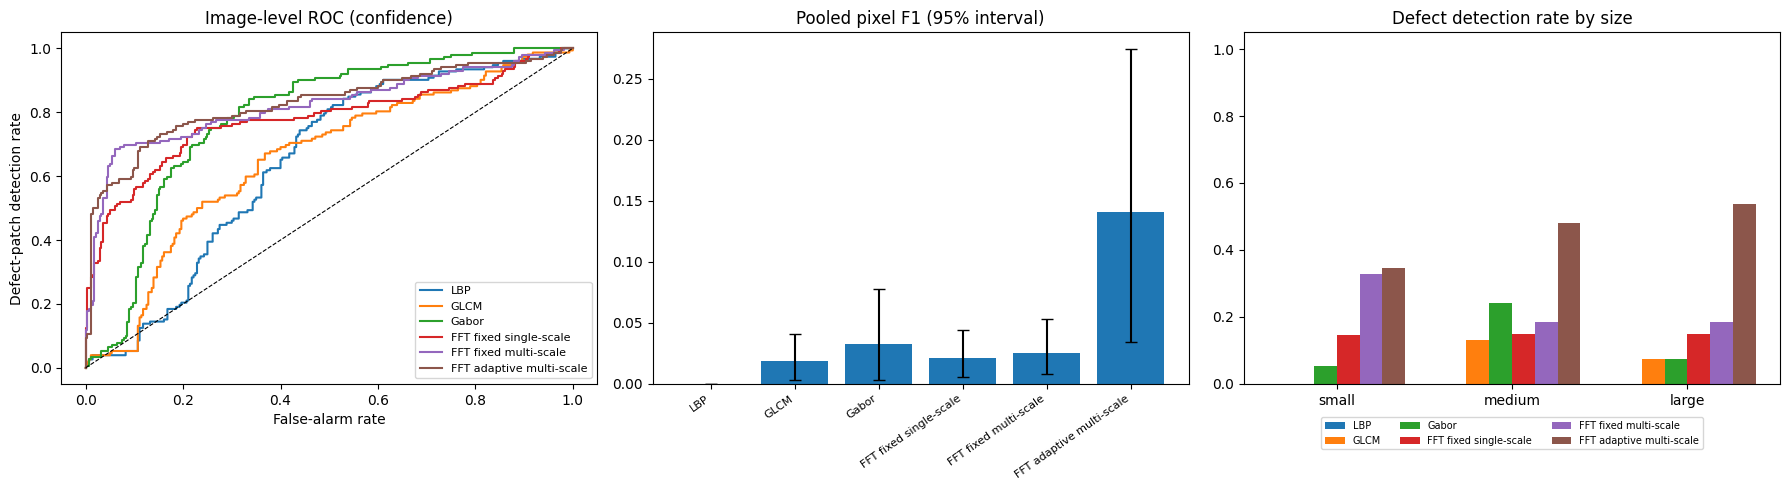

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for m in METHODS:
    d = patch_df[patch_df.method == m]
    fpr, tpr, _ = roc_curve((d.group == "defect").values, d.conf.values)
    axes[0].plot(fpr, tpr, label=m)
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8)
axes[0].set_xlabel("False-alarm rate"); axes[0].set_ylabel("Defect-patch detection rate")
axes[0].set_title("Image-level ROC (confidence)"); axes[0].legend(fontsize=8)

sub = ci_df[ci_df.metric == "Pooled pixel F1"].set_index("method").loc[METHODS]
axes[1].bar(range(len(METHODS)), sub.estimate, yerr=[sub.estimate - sub.ci_low, sub.ci_high - sub.estimate], capsize=4)
axes[1].set_xticks(range(len(METHODS))); axes[1].set_xticklabels(METHODS, rotation=35, ha="right", fontsize=8)
axes[1].set_title("Pooled pixel F1 (95% interval)")

w = 0.13
for i, m in enumerate(METHODS):
    vals = [defect_df_summary.loc[m, f"Detected {s}"] for s in ("small", "medium", "large")]
    axes[2].bar(np.arange(3) + i * w, vals, w, label=m)
axes[2].set_xticks(np.arange(3) + 2.5 * w); axes[2].set_xticklabels(["small", "medium", "large"])
axes[2].set_ylim(0, 1.05); axes[2].set_title("Defect detection rate by size")
axes[2].legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3)
plt.tight_layout()
plt.show()

**SAVE RESULTS**  
Per-patch and per-defect records (with fabric, source and size, ready for the fabric-wise and defect-wise analysis), all summary tables, intervals, and the configuration used.

In [19]:
tag = EVAL_SPLIT + ("_quick" if QUICK else "")
patch_df.to_csv(RESULTS_DIR / f"patch_results_{tag}.csv", index=False)
defect_eval_df.to_csv(RESULTS_DIR / f"defect_results_{tag}.csv", index=False)
pixel_df.to_csv(RESULTS_DIR / f"summary_pixel_{tag}.csv")
defect_df_summary.to_csv(RESULTS_DIR / f"summary_defect_{tag}.csv")
image_df.to_csv(RESULTS_DIR / f"summary_image_{tag}.csv")
ci_df.to_csv(RESULTS_DIR / f"bootstrap_ci_{tag}.csv", index=False)
diff_df.to_csv(RESULTS_DIR / f"paired_differences_{tag}.csv", index=False)
conf_df.to_csv(RESULTS_DIR / f"confidence_check_{tag}.csv", index=False)

meta = dict(cfg={k: (v if not isinstance(v, (np.floating, np.integer)) else float(v)) for k, v in CFG.items()},
            eval_split=EVAL_SPLIT, quick=QUICK, seed=SEED, fabrics=FABRICS, growth_fraction=LOW_FRAC,
            size_cuts=[float(x) for x in size_cuts], n_eval_patches=len(eval_items), n_normal_patches=len(ntest_items),
            adaptive_params={f: dict(P=float(a["P"]), scales=a["scales"], sigma=a["sigma"]) for f, a in adapt_params.items()})
json.dump(meta, open(RESULTS_DIR / f"eval_config_{tag}.json", "w"), indent=2)

print("=" * 60)
print("RESULTS SAVED")
print("=" * 60)
for f in sorted(RESULTS_DIR.glob(f"*_{tag}.*")):
    print(f"  {f.name}")

RESULTS SAVED
  bootstrap_ci_dev.csv
  confidence_check_dev.csv
  defect_results_dev.csv
  eval_config_dev.json
  paired_differences_dev.csv
  patch_results_dev.csv
  summary_defect_dev.csv
  summary_image_dev.csv
  summary_pixel_dev.csv


**WEEK 7 SUMMARY**  
What was evaluated and how.

In [20]:
print("=" * 60)
print("WEEK 7 SUMMARY")
print("=" * 60)
print(f"Methods              : {', '.join(METHODS)}")
print(f"Protocol             : per-fabric or pooled reference on REF patches, normalisation and {CFG['target_fpr']:.0%}-false-alarm threshold on CAL patches,")
print(f"                       identical mask pipeline, interior scoring (margin {CFG['border_margin']} px), growth fraction tuned on DEV per method")
print(f"Evaluated on         : {EVAL_SPLIT.upper()} split, {len(eval_items)} defect patches ({len(areas_all)} defects) and {len(ntest_items)} held-out defect-free patches")
print(f"Intervals            : {CFG['n_boot']} bootstrap resamples of source images")
if EVAL_SPLIT == "dev":
    print("Held out             : TEST split untouched (set EVAL_SPLIT = 'test' once, for the final comparison)")
else:
    print("NOTE                 : TEST split evaluated. Do not retune anything after looking at these numbers.")
print("\nBest by pooled pixel F1      :", max(METHODS, key=lambda m: point[m]["Pooled pixel F1"]))
print("Best by defect detection rate:", max(METHODS, key=lambda m: point[m]["Defect detection rate"]))
print("Best by image-level AUROC    :", max(METHODS, key=lambda m: point[m]["Image-level AUROC"]))
print("\nPixel-level:")
print(pixel_df[["Pooled F1", "AP", "Macro AP"]].round(3).to_string())
print("\nImage-level:")
print(image_df[["F1", "False-alarm rate", "AUROC"]].round(3).to_string())

WEEK 7 SUMMARY
Methods              : LBP, GLCM, Gabor, FFT fixed single-scale, FFT fixed multi-scale, FFT adaptive multi-scale
Protocol             : per-fabric or pooled reference on REF patches, normalisation and 5%-false-alarm threshold on CAL patches,
                       identical mask pipeline, interior scoring (margin 16 px), growth fraction tuned on DEV per method
Evaluated on         : DEV split, 152 defect patches (163 defects) and 280 held-out defect-free patches
Intervals            : 200 bootstrap resamples of source images
Held out             : TEST split untouched (set EVAL_SPLIT = 'test' once, for the final comparison)

Best by pooled pixel F1      : FFT adaptive multi-scale
Best by defect detection rate: FFT adaptive multi-scale
Best by image-level AUROC    : FFT adaptive multi-scale

Pixel-level:
                          Pooled F1     AP  Macro AP
LBP                           0.000  0.031     0.102
GLCM                          0.019  0.030     0.099
Gabor      